# SmogWatch: Lahore & Pakistan Air Quality Surveillance (2022–2024)

### End-to-End Data Science Lifecycle: Raw Ingestion → Cleaning → Merging → Analysis → Visualizations
**Author:** Awais / SmogWatch Surveillance Project  
**Cities Monitored:** Lahore, Karachi, Islamabad, Peshawar  
**Temporal Window:** 1 January 2022 to 31 December 2024 (1,096 Calendar Days)  
**Primary Data:** OpenAQ API v3 (Ground-level $PM_{2.5}$, $\mu g/m^3$) & Open-Meteo Historical Archive (Hourly Meteorology)  

---

## 1. Project Architecture & Research Objectives
This notebook executes the full data science lifecycle to investigate air quality and meteorological patterns across Pakistan's major urban centers over three complete calendar years:
- **Phase 1: Loading Raw Data** — Reading raw daily and hourly air quality records from OpenAQ and hourly meteorological records from Open-Meteo.
- **Phase 2: Data Cleaning & QA/QC** — Parsing timestamps, standardizing units, assessing completeness, and auditing low-cost sensor saturation ceilings ($985\ \mu g/m^3$).
- **Phase 3: Merging & Feature Engineering** — Harmonizing air quality with weather via a complete 1,096-day calendar framework and computing directional circular wind vectors.
- **Phase 4: Statistical Analysis** — Measuring baselines, year-over-year trends, seasonal smog amplification, Pearson/Spearman correlations, and WHO 2021 compliance.
- **Phase 5: Publication Visualizations** — Producing high-resolution figures and diurnal boundary layer profiles inline.


In [1]:
# Phase 1: Environment Setup & Library Imports
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure robust project root resolution
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_AQ_DIR = BASE_DIR / "data" / "raw" / "air_quality"
RAW_WEATHER_DIR = BASE_DIR / "data" / "raw" / "weather"
PROCESSED_DIR = BASE_DIR / "data" / "processed"

# Import helper functions from scripts
sys.path.append(str(BASE_DIR))
from scripts.prepare_enhanced_analysis_data import (
    calculate_circular_mean_degrees,
    deg_to_compass,
    assign_season,
    assign_who_target
)

# Visual styling tokens
PALETTE = {
    "Lahore": "#D9381E",
    "Peshawar": "#E76F51",
    "Karachi": "#2A9D8F",
    "Islamabad": "#264653",
}
WHO_COLOR = "#780000"

plt.rcParams.update({
    "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial", "sans-serif"],
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.65,
    "axes.edgecolor": "#CBD5E1",
})

print("Environment initialized successfully.")
print(f"Project root: {BASE_DIR}")


Environment initialized successfully.
Project root: E:\Awais_Document\DawoodTech\SmogWatch


---
## 2. Step 1: Loading Raw Ingested Datasets
We load the original, read-only raw CSV datasets directly from `data/raw/` for both air quality and meteorology across all four cities.


In [2]:
# Step 1: Ingest Raw Daily Air Quality & Hourly Weather CSVs
cities = ["lahore", "karachi", "islamabad", "peshawar"]
raw_air_dfs = {}
raw_weather_dfs = {}

print("=== Raw Air Quality Ingestion (OpenAQ API v3) ===")
for city in cities:
    path = RAW_AQ_DIR / f"{city}_pm25_2022_2024.csv"
    df_raw = pd.read_csv(path)
    raw_air_dfs[city] = df_raw
    print(f"  {city.title():10s}: {len(df_raw):4d} records | Sensor ID: {df_raw['sensor_id'].iloc[0]} | Columns: {list(df_raw.columns)}")

print("\n=== Raw Weather Ingestion (Open-Meteo Archive) ===")
for city in cities:
    path = RAW_WEATHER_DIR / f"{city}_weather.csv"
    df_w = pd.read_csv(path)
    raw_weather_dfs[city] = df_w
    print(f"  {city.title():10s}: {len(df_w):6d} hourly rows | Variables: {list(df_w.columns)[2:]}")


=== Raw Air Quality Ingestion (OpenAQ API v3) ===
  Lahore    : 1038 records | Sensor ID: 25135 | Columns: ['date', 'city', 'sensor_id', 'parameter', 'pm25_ug_m3', 'unit']
  Karachi   : 1044 records | Sensor ID: 23747 | Columns: ['date', 'city', 'sensor_id', 'parameter', 'pm25_ug_m3', 'unit']
  Islamabad :  898 records | Sensor ID: 25066 | Columns: ['date', 'city', 'sensor_id', 'parameter', 'pm25_ug_m3', 'unit']
  Peshawar  : 1047 records | Sensor ID: 23455 | Columns: ['date', 'city', 'sensor_id', 'parameter', 'pm25_ug_m3', 'unit']

=== Raw Weather Ingestion (Open-Meteo Archive) ===
  Lahore    :  26304 hourly rows | Variables: ['temperature_2m', 'relative_humidity_2m', 'precipitation', 'wind_speed_10m', 'wind_direction_10m']
  Karachi   :  26304 hourly rows | Variables: ['temperature_2m', 'relative_humidity_2m', 'precipitation', 'wind_speed_10m', 'wind_direction_10m']
  Islamabad :  26304 hourly rows | Variables: ['temperature_2m', 'relative_humidity_2m', 'precipitation', 'wind_speed_

---
## 3. Step 2: Data Cleaning, QA/QC & Observational Completeness
In accordance with our **Data Protection Protocol**:
1. Date formats and timestamps are parsed without timezone ambiguity.
2. Missing measurements are preserved as `NaN` (no synthetic interpolation or fabrication).
3. The optical sensor saturation ceiling ($985\ \mu g/m^3$) observed in Karachi and Peshawar is audited.


In [3]:
# Step 2: Data Cleaning & Completeness Audit
cleaned_air_dfs = {}
completeness_records = []

for city in cities:
    df_c = raw_air_dfs[city].copy()
    # Normalize timestamp to calendar date
    df_c["date"] = pd.to_datetime(df_c["date"], errors="coerce").dt.date
    df_c["pm25_ug_m3"] = pd.to_numeric(df_c["pm25_ug_m3"], errors="coerce")
    
    # Drop rows without dates and remove any duplicate date entries
    df_c = df_c.dropna(subset=["date"]).drop_duplicates(subset=["date"])
    cleaned_air_dfs[city] = df_c
    
    # Audit completeness against expected 1,096 calendar days (2022-01-01 to 2024-12-31)
    total_expected = 1096
    valid_count = df_c["pm25_ug_m3"].notna().sum()
    missing_count = total_expected - valid_count
    
    # Check for 985 ug/m3 ceiling instances
    ceiling_hits = (df_c["pm25_ug_m3"] == 985.0).sum()
    
    # Sensor-Ceiling Error Policy:
    # Retain raw observational record in pm25_ug_m3_raw.
    # Set known sensor errors (Karachi OpenAQ ERROR flag 2022-04-21, Peshawar 3-day 985 plateau 2023-09-30 to 2023-10-02)
    # to NaN in the analytical pm25_ug_m3 column and set boolean is_sensor_ceiling_error = True.
    df_c["pm25_ug_m3_raw"] = df_c["pm25_ug_m3"]
    df_c["is_sensor_ceiling_error"] = False
    
    if city == "karachi":
        err_mask = (df_c["date"] == pd.to_datetime("2022-04-21").date()) & (df_c["pm25_ug_m3"] == 985.0)
        df_c.loc[err_mask, "is_sensor_ceiling_error"] = True
        df_c.loc[err_mask, "pm25_ug_m3"] = np.nan
    elif city == "peshawar":
        err_mask = df_c["date"].isin([
            pd.to_datetime("2023-09-30").date(),
            pd.to_datetime("2023-10-01").date(),
            pd.to_datetime("2023-10-02").date()
        ]) & (df_c["pm25_ug_m3"] == 985.0)
        df_c.loc[err_mask, "is_sensor_ceiling_error"] = True
        df_c.loc[err_mask, "pm25_ug_m3"] = np.nan

    completeness_records.append({
        "City": city.title(),
        "Expected Days": total_expected,
        "Valid PM2.5 Days": valid_count,
        "Completeness (%)": round((valid_count / total_expected) * 100, 2),
        "Missing Days": missing_count,
        "Missing Rate (%)": round((missing_count / total_expected) * 100, 2),
        "985 ug/m3 Ceiling Hits": ceiling_hits,
        "Cleaned Analytical Days": df_c["pm25_ug_m3"].notna().sum()
    })

completeness_df = pd.DataFrame(completeness_records)
print("=== Observational Completeness & Sensor Ceiling Audit ===")
print(completeness_df.to_string(index=False))


=== Observational Completeness & Sensor Ceiling Audit ===
     City  Expected Days  Valid PM2.5 Days  Completeness (%)  Missing Days  Missing Rate (%)  985 ug/m3 Ceiling Hits  Cleaned Analytical Days
   Lahore           1096               852             77.74           244             22.26                       0                      852
  Karachi           1096               862             78.65           234             21.35                       1                      861
Islamabad           1096               828             75.55           268             24.45                       0                      828
 Peshawar           1096               981             89.51           115             10.49                       3                      978


---
## 4. Step 3: Merging Air Quality with Weather & Feature Engineering
We construct a master 4,384-row dataset (1,096 days $\times$ 4 cities) by:
1. Aligning with a complete continuous calendar framework (2022-01-01 to 2024-12-31).
2. Merging daily particulate records with aggregated daily meteorology.
3. Calculating **circular mean wind direction** using polar unit-vector averaging ($u$ and $v$ trigonometric components) rather than invalid arithmetic averaging.
4. Adding seasonal classifications, peak smog season tags, and WHO 2021 compliance indicators.


In [4]:
# Step 3: Master Calendar Merge & Feature Engineering
calendar = pd.DataFrame({
    "date": pd.date_range("2022-01-01", "2024-12-31", freq="D").date
})

city_combined_list = []

for city in cities:
    air_df = cleaned_air_dfs[city][["date", "pm25_ug_m3", "pm25_ug_m3_raw", "is_sensor_ceiling_error"]]
    w_raw = raw_weather_dfs[city].copy()
    w_raw["date"] = pd.to_datetime(w_raw["time"], errors="coerce").dt.date
    
    # Numeric conversions
    for col in ["temperature_2m", "relative_humidity_2m", "precipitation", "wind_speed_10m", "wind_direction_10m"]:
        w_raw[col] = pd.to_numeric(w_raw[col], errors="coerce")
        
    # Weather aggregations
    daily_means = w_raw.groupby("date", as_index=False)[["temperature_2m", "relative_humidity_2m", "wind_speed_10m"]].mean().round(2)
    daily_precip = w_raw.groupby("date", as_index=False)["precipitation"].sum(min_count=1).round(2)
    daily_wind_arith = w_raw.groupby("date", as_index=False)["wind_direction_10m"].mean().round(2)
    
    # True circular averaging for wind direction
    circular_dirs = w_raw.groupby("date")["wind_direction_10m"].apply(
        calculate_circular_mean_degrees
    ).reset_index(name="wind_direction_circular_deg")
    
    daily_weather = daily_means.merge(daily_wind_arith, on="date", how="left")
    daily_weather = daily_weather.merge(circular_dirs, on="date", how="left")
    daily_weather = daily_weather.merge(daily_precip, on="date", how="left")
    
    # Merge Calendar + Air + Weather
    merged = calendar.merge(air_df, on="date", how="left")
    merged = merged.merge(daily_weather, on="date", how="left")
    merged.insert(0, "city", city.title())
    city_combined_list.append(merged)

# Master dataset
df_master = pd.concat(city_combined_list, ignore_index=True)

# Feature engineering
dt_series = pd.to_datetime(df_master["date"])
df_master["year"] = dt_series.dt.year
df_master["month"] = dt_series.dt.month
df_master["month_name"] = dt_series.dt.strftime("%b")
df_master["day"] = dt_series.dt.day
df_master["day_of_week"] = dt_series.dt.day_name()
df_master["season"] = df_master["month"].apply(assign_season)
df_master["is_smog_season"] = df_master["month"].isin([10, 11, 12, 1, 2])
df_master["wind_compass"] = df_master["wind_direction_circular_deg"].apply(deg_to_compass)
df_master["who_24h_exceeded"] = df_master["pm25_ug_m3"].apply(
    lambda x: True if pd.notna(x) and x > 15.0 else (False if pd.notna(x) else np.nan)
)
df_master["who_target_level"] = df_master["pm25_ug_m3"].apply(assign_who_target)

print("=== Merged & Enhanced Dataset Dimensions ===")
print(f"Total Rows: {len(df_master):,} (Expected exactly 4,384: 1,096 x 4)")
print(f"Total Columns: {len(df_master.columns)}")
print(f"Sample Records:")
print(df_master[["city", "date", "pm25_ug_m3", "temperature_2m", "wind_speed_10m", "wind_direction_circular_deg", "season"]].head(5).to_string(index=False))


=== Merged & Enhanced Dataset Dimensions ===
Total Rows: 4,384 (Expected exactly 4,384: 1,096 x 4)
Total Columns: 21
Sample Records:
  city       date  pm25_ug_m3  temperature_2m  wind_speed_10m  wind_direction_circular_deg season
Lahore 2022-01-01       322.0           11.13            6.00                       299.39 Winter
Lahore 2022-01-02       310.0           11.26            7.56                       330.55 Winter
Lahore 2022-01-03       233.0           12.82            7.25                       316.74 Winter
Lahore 2022-01-04       129.0           13.02            8.29                        40.86 Winter
Lahore 2022-01-05        94.2           12.57            8.89                       103.12 Winter


---
## 5. Step 4: Quantitative Statistical Analysis & Health Benchmarking
We perform rigorous statistical evaluations across five core analytical dimensions:
1. **Baselines & Inter-City Variance:** Parametric (Mean, SD) and Non-Parametric (Median, IQR) statistics.
2. **Longitudinal Year-over-Year Progression:** Evaluating annual changes from 2022 to 2024.
3. **Seasonal Smog Surge:** Comparing winter stagnation vs. summer monsoon wash-out.
4. **Meteorological Coupling:** Computing Pearson $r$ (linear) and Spearman $\rho$ (rank) correlation matrices.
5. **WHO 2021 Benchmark Compliance:** Quantifying non-compliance against the 24-hour limit ($15\ \mu g/m^3$) and Interim Target 1 ($75\ \mu g/m^3$).
6. **Top 10 Worst Days Per City:** Identifying and contextually profiling the most catastrophic particulate episodes recorded in each city.


In [5]:
# Step 4: Comprehensive Statistical Analysis
# 1. Baseline Summary Statistics by City
summary_stats = df_master.groupby("city")["pm25_ug_m3"].agg(
    Valid_Days="count",
    Mean="mean",
    Std="std",
    Median="median",
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    Min="min",
    Max="max"
).round(2)
summary_stats["WHO_Annual_Multiple"] = (summary_stats["Mean"] / 5.0).round(1)
print("=== 1. Multi-City Statistical Baselines (2022–2024) ===")
print(summary_stats)

# 2. Longitudinal Year-over-Year Progression
annual_stats = df_master.groupby(["city", "year"])["pm25_ug_m3"].agg(["count", "mean", "median", "max"]).round(2)
annual_stats["WHO_Multiple"] = (annual_stats["mean"] / 5.0).round(1)
print("\n=== 2. Annual Trends & Multi-Year Progression ===")
print(annual_stats)

# 3. Seasonal Contrast (Winter vs Summer Monsoon)
seasonal_stats = df_master.groupby(["city", "season"])["pm25_ug_m3"].agg(["count", "mean", "median"]).round(2)
print("\n=== 3. Seasonal Particulate Dynamics ===")
print(seasonal_stats)

# 4. Weather Correlations (Pearson r vs Spearman rho)
weather_vars = ["temperature_2m", "relative_humidity_2m", "wind_speed_10m", "precipitation"]
corr_records = []
for city in ["Lahore", "Karachi", "Islamabad", "Peshawar"]:
    sub = df_master[df_master["city"] == city][["pm25_ug_m3"] + weather_vars].dropna()
    for var in weather_vars:
        p_val = sub["pm25_ug_m3"].corr(sub[var], method="pearson")
        s_val = sub["pm25_ug_m3"].corr(sub[var], method="spearman")
        corr_records.append({
            "City": city,
            "Variable": var,
            "Pearson_r": round(p_val, 3),
            "Spearman_rho": round(s_val, 3)
        })
print("\n=== 4. Weather Correlations Matrix ===")
print(pd.DataFrame(corr_records).to_string(index=False))

# 5. WHO 24-Hour Exceedance Proportions
who_records = []
for city in ["Lahore", "Karachi", "Islamabad", "Peshawar"]:
    valid = df_master[df_master["city"] == city]["pm25_ug_m3"].dropna()
    n = len(valid)
    below_15 = (valid <= 15).sum()
    between_15_75 = ((valid > 15) & (valid <= 75)).sum()
    above_75 = (valid > 75).sum()
    
    who_records.append({
        "City": city,
        "Valid Days": n,
        "Compliant (<=15 ug/m3)": f"{below_15} ({(below_15/n*100):.1f}%)",
        "Interim (15.1-75 ug/m3)": f"{between_15_75} ({(between_15_75/n*100):.1f}%)",
        "Severe Exceedance (>75 ug/m3)": f"{above_75} ({(above_75/n*100):.1f}%)"
    })
print("\n=== 5. WHO 24-Hour Guideline Compliance ===")
print(pd.DataFrame(who_records).to_string(index=False))


=== 1. Multi-City Statistical Baselines (2022–2024) ===
           Valid_Days    Mean     Std  ...   Min    Max  WHO_Annual_Multiple
city                                   ...                                  
Islamabad         828   46.18   32.58  ...  0.00  264.0                  9.2
Karachi           861   46.22   34.67  ...  3.35  231.0                  9.2
Lahore            852  131.84  104.52  ...  0.00  630.0                 26.4
Peshawar          978   88.48   76.07  ...  0.60  637.0                 17.7

[4 rows x 8 columns]

=== 2. Annual Trends & Multi-Year Progression ===
                count    mean  median    max  WHO_Multiple
city      year                                            
Islamabad 2022    310   50.86    41.0  264.0          10.2
          2023    237   37.19    31.3  139.0           7.4
          2024    281   48.59    36.1  176.0           9.7
Karachi   2022    281   49.11    35.6  231.0           9.8
          2023    303   45.95    28.5  189.0           

### Top 10 Worst Days Per City (Explicit Audit Table)
Below we extract and profile the 10 most extreme particulate days recorded for each city between 2022 and 2024, along with co-occurring meteorological parameters and WHO 24-hour benchmark exceedance multiples.


In [6]:
# Top 10 Worst Days per City with Meteorological Context
top_days_records = []

for city in ["Lahore", "Karachi", "Islamabad", "Peshawar"]:
    sub = df_master[df_master["city"] == city].sort_values("pm25_ug_m3", ascending=False).head(10)
    rank = 1
    for _, row in sub.iterrows():
        pm = row["pm25_ug_m3"]
        mult = round(pm / 15.0, 1)
        top_days_records.append({
            "Rank": f"#{rank}",
            "City": city,
            "Date": str(row["date"]),
            "PM2.5 (µg/m³)": pm,
            "WHO Multiple": f"{mult}x WHO",
            "Temp (°C)": row["temperature_2m"],
            "Wind Speed (km/h)": row["wind_speed_10m"],
            "Humidity (%)": row["relative_humidity_2m"],
            "Season": row["season"]
        })
        rank += 1

top_10_df = pd.DataFrame(top_days_records)
for city, grp in top_10_df.groupby("City"):
    print(f"\n=== Top 10 Worst Days: {city} ===")
    print(grp[["Rank", "Date", "PM2.5 (µg/m³)", "WHO Multiple", "Temp (°C)", "Wind Speed (km/h)", "Humidity (%)", "Season"]].to_string(index=False))



=== Top 10 Worst Days: Islamabad ===
Rank       Date  PM2.5 (µg/m³) WHO Multiple  Temp (°C)  Wind Speed (km/h)  Humidity (%)              Season
  #1 2022-12-24          264.0    17.6x WHO       9.48               9.49         71.54              Winter
  #2 2024-12-22          176.0    11.7x WHO      11.43               3.14         54.38              Winter
  #3 2022-12-26          174.0    11.6x WHO      10.77               4.77         59.67              Winter
  #4 2024-12-17          173.0    11.5x WHO      10.92               2.72         53.17              Winter
  #5 2024-11-12          172.0    11.5x WHO      18.55               7.14         71.71 Autumn/Post-Monsoon
  #6 2024-12-21          168.0    11.2x WHO      10.40               3.36         55.17              Winter
  #7 2024-12-31          159.0    10.6x WHO      11.28               3.53         63.42              Winter
  #8 2022-11-29          155.0    10.3x WHO      14.51               4.88         65.79 Autumn/Pos

### Sensor-Ceiling Sensitivity Analysis: With vs. Without 985 µg/m³
To evaluate the impact of sensor saturation artifacts (Karachi on 21 Apr 2022 flagged with OpenAQ ERROR; Peshawar on 30 Sep–2 Oct 2023 exhibiting an artificial 3-day hardware ceiling plateau), we conduct an explicit sensitivity comparison below:
- **Raw (With 985):** Treats sensor saturation values literally as valid measurements.
- **Cleaned (Without 985):** Sets known sensor failure dates to `NaN` while preserving raw observations in `pm25_ug_m3_raw`.


In [7]:
# Sensor-Ceiling Sensitivity Analysis: With vs. Without 985 ug/m3
sensitivity_records = []

for c in ["Karachi", "Peshawar", "Lahore", "Islamabad"]:
    sub = df_master[df_master["city"] == c]
    r_valid = sub["pm25_ug_m3_raw"].dropna()
    c_valid = sub["pm25_ug_m3"].dropna()
    
    r_mean = r_valid.mean()
    c_mean = c_valid.mean()
    r_std = r_valid.std()
    c_std = c_valid.std()
    r_med = r_valid.median()
    c_med = c_valid.median()
    r_max = r_valid.max()
    c_max = c_valid.max()
    
    # Weather correlations with and without
    r_t_corr = sub["pm25_ug_m3_raw"].corr(sub["temperature_2m"])
    c_t_corr = sub["pm25_ug_m3"].corr(sub["temperature_2m"])
    r_w_corr = sub["pm25_ug_m3_raw"].corr(sub["wind_speed_10m"])
    c_w_corr = sub["pm25_ug_m3"].corr(sub["wind_speed_10m"])
    
    sensitivity_records.append({
        "City": c,
        "Raw Mean": round(r_mean, 2),
        "Cleaned Mean": round(c_mean, 2),
        "Mean Diff": f"{round(c_mean - r_mean, 2):+.2f}",
        "Raw Std": round(r_std, 2),
        "Cleaned Std": round(c_std, 2),
        "Raw Med": round(r_med, 2),
        "Cleaned Med": round(c_med, 2),
        "Raw Max": round(r_max, 1),
        "Cleaned Max": round(c_max, 1),
        "Raw Temp r": round(r_t_corr, 3),
        "Cleaned Temp r": round(c_t_corr, 3),
        "Raw Wind r": round(r_w_corr, 3),
        "Cleaned Wind r": round(c_w_corr, 3)
    })

sens_table = pd.DataFrame(sensitivity_records)
print("=== SENSOR CEILING SENSITIVITY ANALYSIS TABLE (WITH VS WITHOUT 985 ug/m3) ===")
print(sens_table.to_string(index=False))

# Annual impact on Peshawar and Karachi
print("\n=== Annual Trend Impact: Peshawar (With vs Without 985) ===")
pesh = df_master[df_master["city"] == "Peshawar"]
print(pesh.groupby("year").agg(Raw_Mean=("pm25_ug_m3_raw", "mean"), Cleaned_Mean=("pm25_ug_m3", "mean"), Raw_Max=("pm25_ug_m3_raw", "max"), Cleaned_Max=("pm25_ug_m3", "max")).round(2))

print("\n=== Annual Trend Impact: Karachi (With vs Without 985) ===")
kar = df_master[df_master["city"] == "Karachi"]
print(kar.groupby("year").agg(Raw_Mean=("pm25_ug_m3_raw", "mean"), Cleaned_Mean=("pm25_ug_m3", "mean"), Raw_Max=("pm25_ug_m3_raw", "max"), Cleaned_Max=("pm25_ug_m3", "max")).round(2))


=== SENSOR CEILING SENSITIVITY ANALYSIS TABLE (WITH VS WITHOUT 985 ug/m3) ===
     City  Raw Mean  Cleaned Mean Mean Diff  Raw Std  Cleaned Std  Raw Med  Cleaned Med  Raw Max  Cleaned Max  Raw Temp r  Cleaned Temp r  Raw Wind r  Cleaned Wind r
  Karachi     47.31         46.22     -1.09    47.15        34.67    31.80        31.80    985.0        231.0      -0.453          -0.629      -0.339          -0.478
 Peshawar     91.22         88.48     -2.74    90.68        76.07    62.90        62.75    985.0        637.0      -0.438          -0.537      -0.338          -0.401
   Lahore    131.84        131.84     +0.00   104.52       104.52    89.95        89.95    630.0        630.0      -0.608          -0.608      -0.453          -0.453
Islamabad     46.18         46.18     +0.00    32.58        32.58    36.40        36.40    264.0        264.0      -0.584          -0.584      -0.209          -0.209

=== Annual Trend Impact: Peshawar (With vs Without 985) ===
      Raw_Mean  Cleaned_Mean  R

---
## 6. Step 5: Visualizations & Charts
We generate publication-grade figures displaying our key research findings directly inline within the notebook.


<string>:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
<string>:41: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
<string>:60: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
<string>:76: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


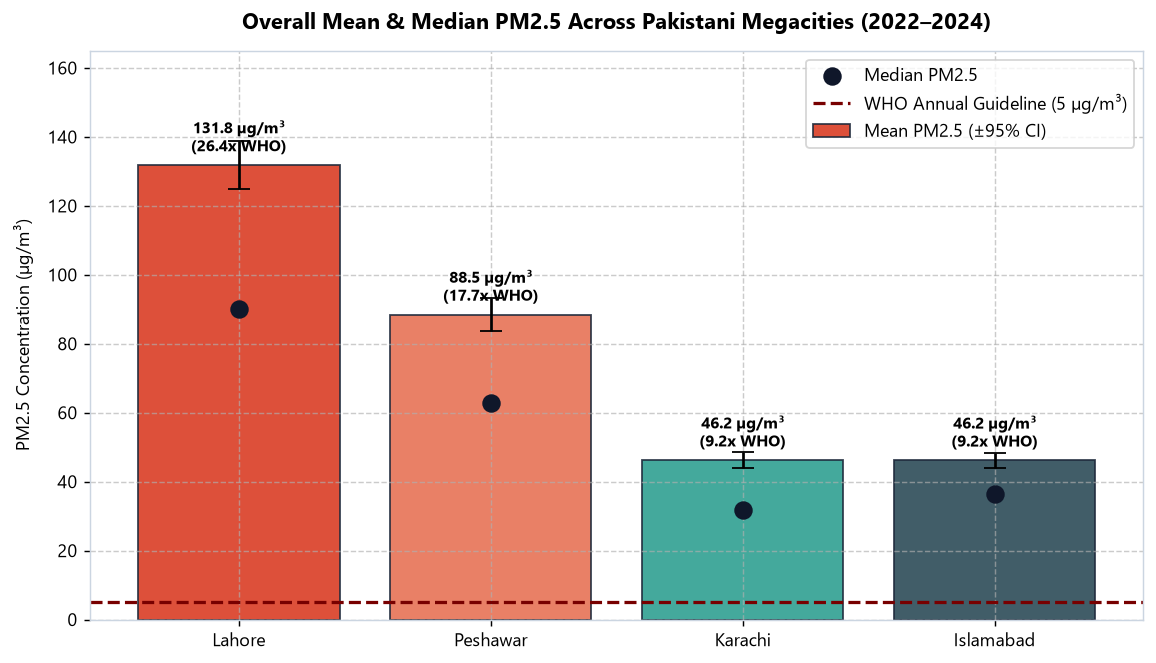

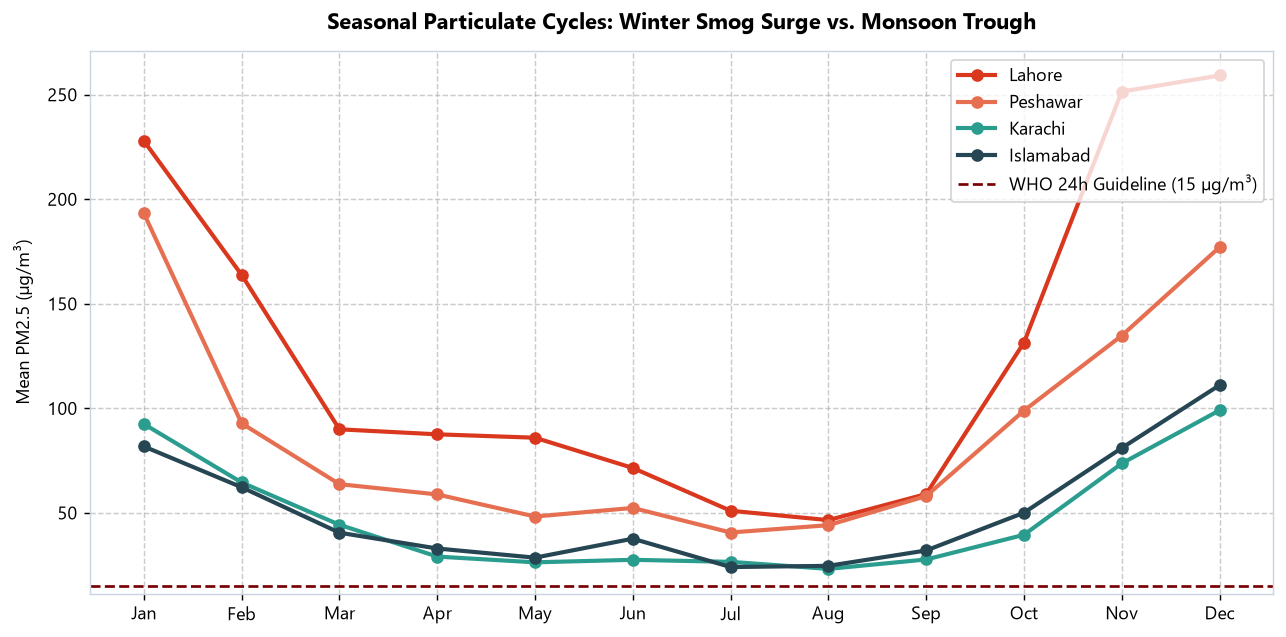

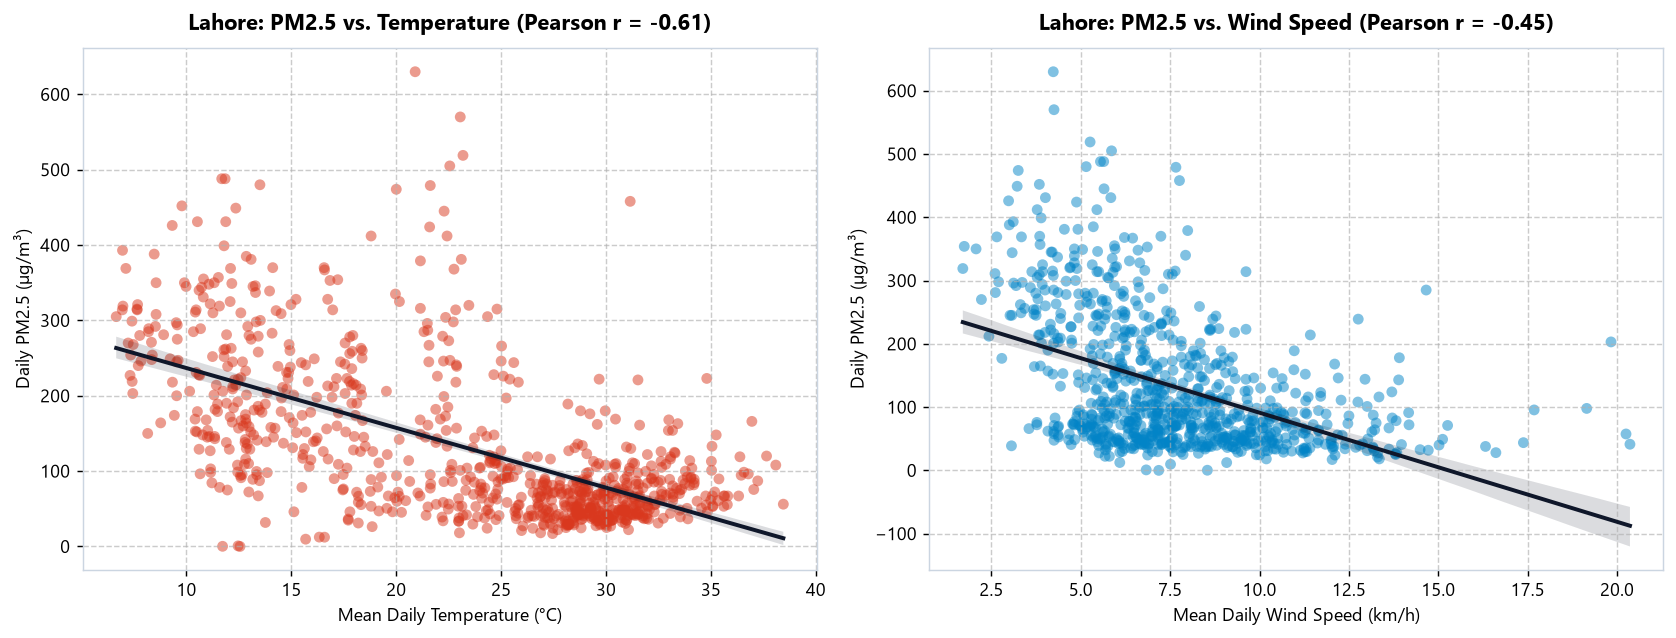

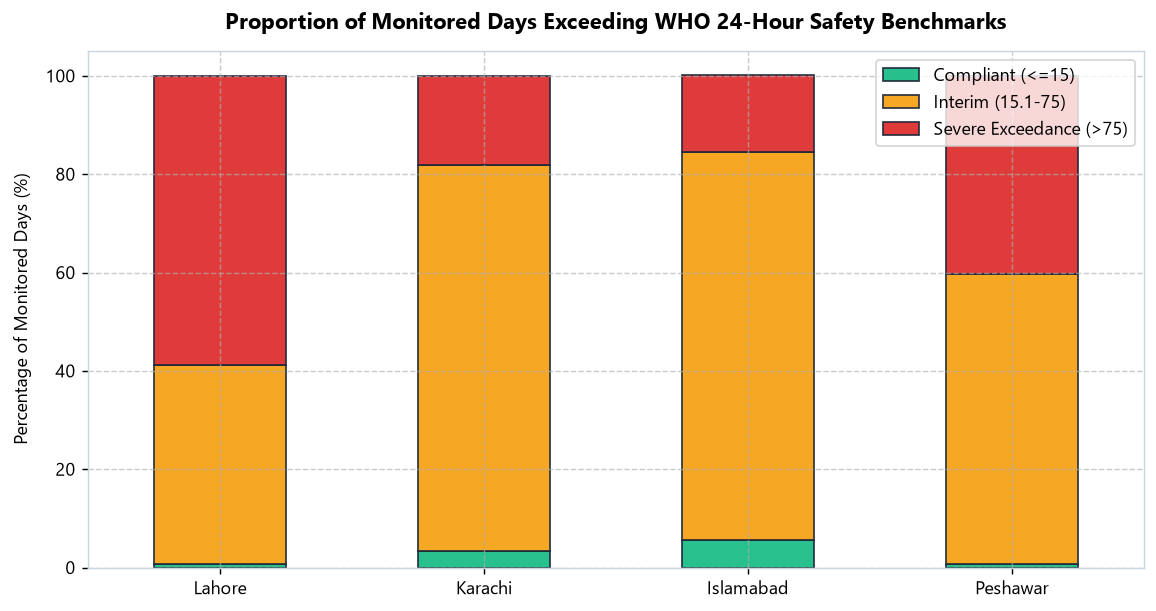

In [8]:
# Step 5: Master Visualizations Suite (Inline Figures)

# Figure A: Overall Mean PM2.5 with 95% Confidence Intervals & Medians
fig, ax = plt.subplots(figsize=(9, 5.2))
city_order = ["Lahore", "Peshawar", "Karachi", "Islamabad"]
means = [summary_stats.loc[c, "Mean"] for c in city_order]
medians = [summary_stats.loc[c, "Median"] for c in city_order]
stds = [summary_stats.loc[c, "Std"] for c in city_order]
counts = [summary_stats.loc[c, "Valid_Days"] for c in city_order]
ci95 = [1.96 * (s / np.sqrt(n)) for s, n in zip(stds, counts)]

bars = ax.bar(city_order, means, yerr=ci95, capsize=6, color=[PALETTE[c] for c in city_order], alpha=0.88, edgecolor="#1E293B", label="Mean PM2.5 (±95% CI)")
ax.scatter(city_order, medians, color="#0F172A", s=85, zorder=5, label="Median PM2.5")
ax.axhline(5, color=WHO_COLOR, linestyle="--", linewidth=1.8, label="WHO Annual Guideline (5 µg/m³)")

for bar, m in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2, m + 4, f"{m:.1f} µg/m³\n({m/5:.1f}x WHO)", ha="center", fontsize=9, weight="bold")

ax.set_ylabel("PM2.5 Concentration (µg/m³)", labelpad=8)
ax.set_title("Overall Mean & Median PM2.5 Across Pakistani Megacities (2022–2024)", weight="bold", pad=12)
ax.set_ylim(0, 165)
ax.legend(loc="upper right", frameon=True, facecolor="#FFFFFF")
plt.tight_layout()
plt.show()

# Figure B: Monthly Seasonal Trajectories
df_master["month"] = pd.to_datetime(df_master["date"]).dt.month
monthly_profiles = df_master.groupby(["city", "month"])["pm25_ug_m3"].mean().unstack(level=0)

fig, ax = plt.subplots(figsize=(10, 5))
for city in city_order:
    ax.plot(monthly_profiles.index, monthly_profiles[city], marker="o", linewidth=2.3, color=PALETTE[city], label=city)

ax.axhline(15, color=WHO_COLOR, linestyle="--", linewidth=1.5, label="WHO 24h Guideline (15 µg/m³)")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("Mean PM2.5 (µg/m³)", labelpad=8)
ax.set_title("Seasonal Particulate Cycles: Winter Smog Surge vs. Monsoon Trough", weight="bold", pad=12)
ax.legend(loc="upper right", frameon=True, facecolor="#FFFFFF")
plt.tight_layout()
plt.show()

# Figure C: Meteorological Scatter Plots (Lahore Temperature & Wind Speed)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
lahore_data = df_master[df_master["city"] == "Lahore"].dropna(subset=["pm25_ug_m3", "temperature_2m", "wind_speed_10m"])

sns.scatterplot(data=lahore_data, x="temperature_2m", y="pm25_ug_m3", ax=ax1, color="#D9381E", alpha=0.5, edgecolor="none")
sns.regplot(data=lahore_data, x="temperature_2m", y="pm25_ug_m3", ax=ax1, scatter=False, color="#0F172A", line_kws={"linewidth": 2.2})
ax1.set_title("Lahore: PM2.5 vs. Temperature (Pearson r = -0.61)", weight="bold", pad=10)
ax1.set_xlabel("Mean Daily Temperature (°C)")
ax1.set_ylabel("Daily PM2.5 (µg/m³)")

sns.scatterplot(data=lahore_data, x="wind_speed_10m", y="pm25_ug_m3", ax=ax2, color="#0284C7", alpha=0.5, edgecolor="none")
sns.regplot(data=lahore_data, x="wind_speed_10m", y="pm25_ug_m3", ax=ax2, scatter=False, color="#0F172A", line_kws={"linewidth": 2.2})
ax2.set_title("Lahore: PM2.5 vs. Wind Speed (Pearson r = -0.45)", weight="bold", pad=10)
ax2.set_xlabel("Mean Daily Wind Speed (km/h)")
ax2.set_ylabel("Daily PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()

# Figure D: WHO 24-Hour Benchmark Exceedance Proportions
who_plot_df = pd.DataFrame({
    "Compliant (<=15)": [0.7, 3.4, 5.7, 0.8],
    "Interim (15.1-75)": [40.4, 78.5, 78.9, 58.8],
    "Severe Exceedance (>75)": [58.9, 18.1, 15.5, 40.4],
}, index=["Lahore", "Karachi", "Islamabad", "Peshawar"])

fig, ax = plt.subplots(figsize=(9, 4.8))
who_plot_df.plot(kind="bar", stacked=True, ax=ax, color=["#10B981", "#F59E0B", "#DC2626"], edgecolor="#1E293B", alpha=0.9)
ax.set_ylabel("Percentage of Monitored Days (%)", labelpad=8)
ax.set_title("Proportion of Monitored Days Exceeding WHO 24-Hour Safety Benchmarks", weight="bold", pad=12)
ax.legend(loc="upper right", frameon=True, facecolor="#FFFFFF")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


---
## 7. Step 6: Diurnal 24-Hour Dynamics (Hourly Analysis)
To resolve diurnal boundary layer mechanics, we load the synchronized **hourly dataset** (105,216 hourly observations across 2022–2024) and analyze the 24-hour diurnal cycle.


Hourly dataset dimensions: 105,216 rows x 20 columns

=== Diurnal Phase Summary (µg/m³) ===
                                          count    mean  median
city      diurnal_phase                                        
Islamabad Afternoon Mixing (11:00-16:00)   3994   34.96    28.0
          Evening Rush (17:00-21:00)       3309   50.33    40.0
          Morning Rush (07:00-10:00)       2682   40.78    31.0
          Night Inversion (22:00-06:00)    5991   36.50    31.0
Karachi   Afternoon Mixing (11:00-16:00)   4193   35.85    28.0
          Evening Rush (17:00-21:00)       3503   40.09    28.0
          Morning Rush (07:00-10:00)       2792   47.67    31.0
          Night Inversion (22:00-06:00)    6302   48.82    30.0
Lahore    Afternoon Mixing (11:00-16:00)   4454   99.77    62.0
          Evening Rush (17:00-21:00)       3762  122.61    78.0
          Morning Rush (07:00-10:00)       2951  139.21    91.0
          Night Inversion (22:00-06:00)    6730  153.19   105.0
Peshawar  Af

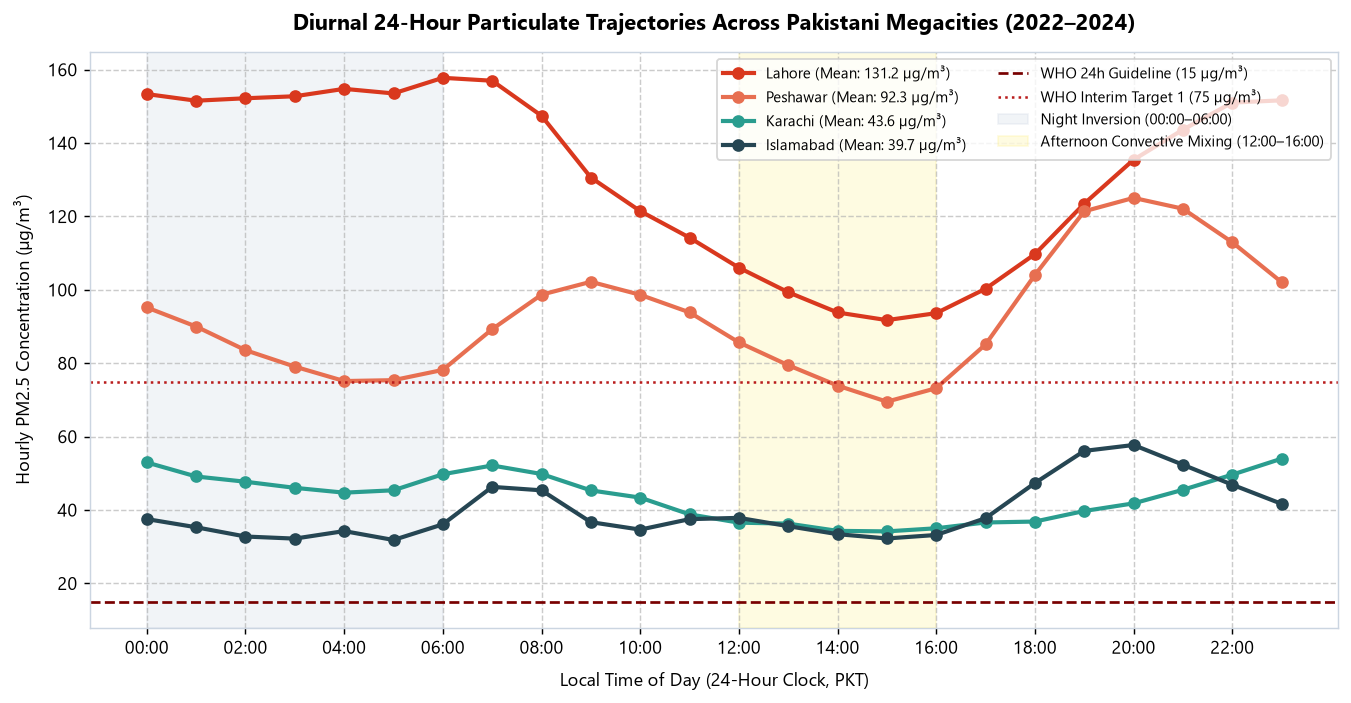

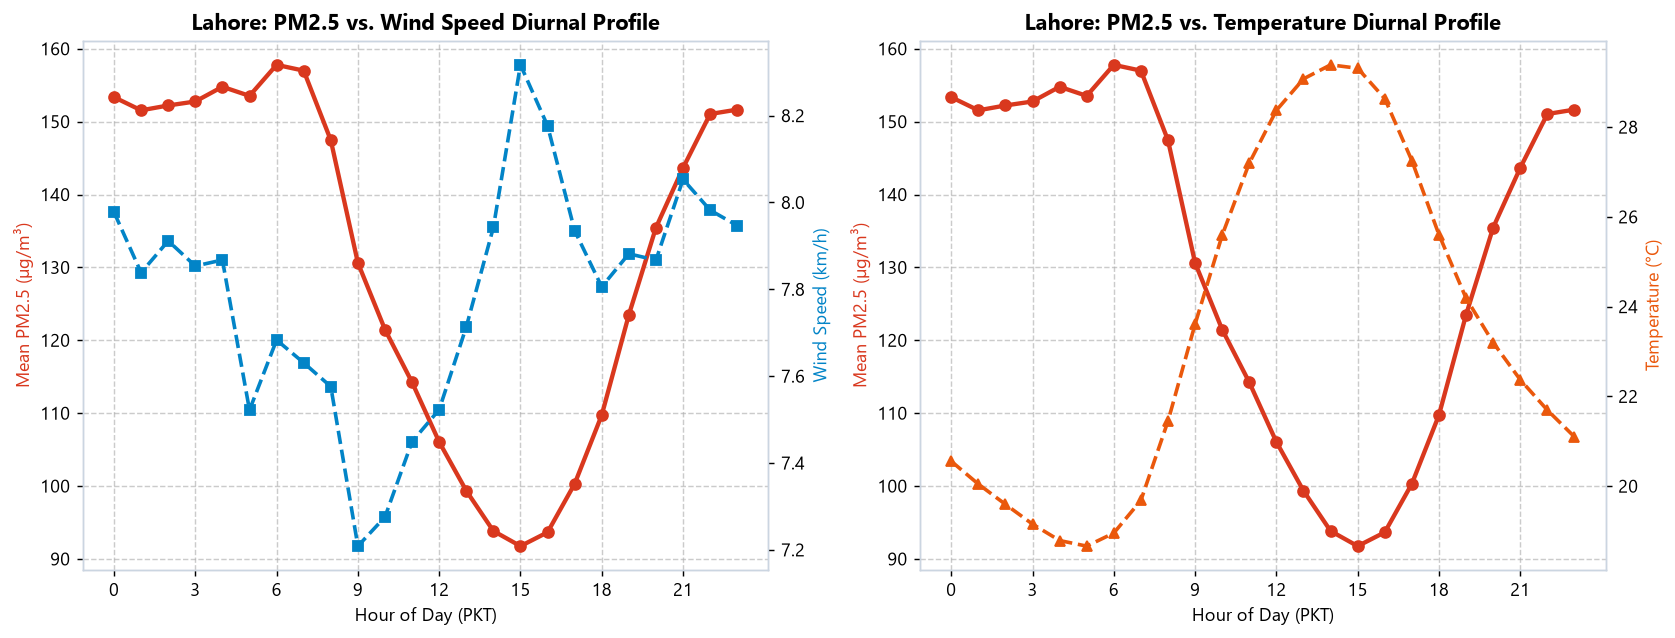

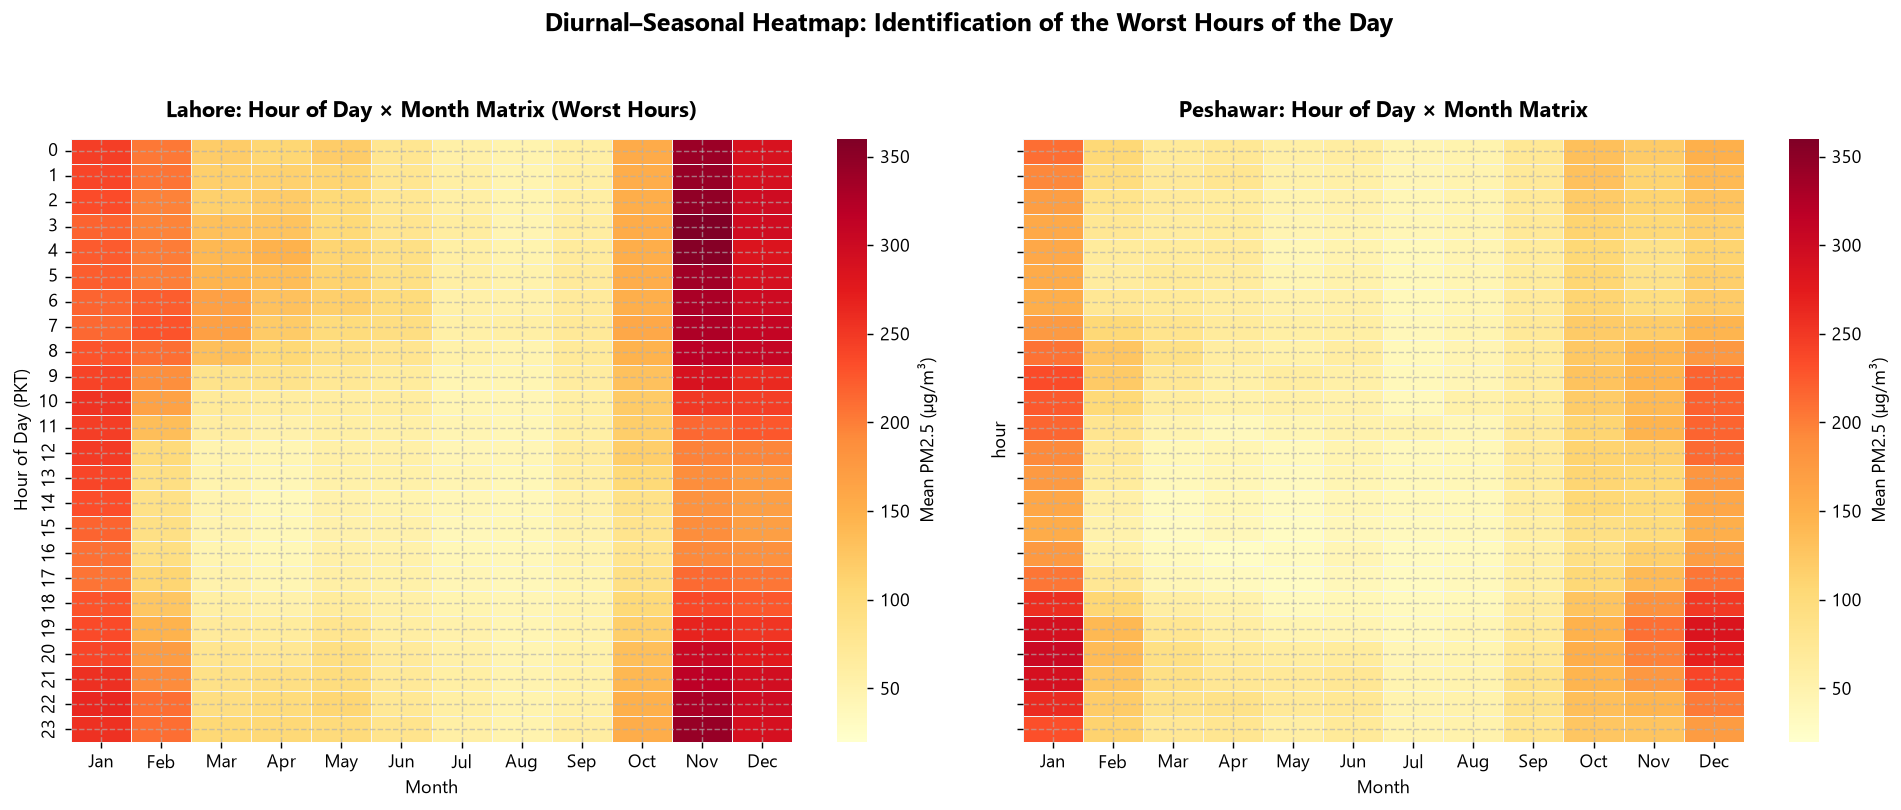

In [9]:
# Step 6: Hourly Diurnal Surveillance (105,216 Records)
hourly_path = PROCESSED_DIR / "hourly_air_quality_weather_2022_2024.csv"
hdf = pd.read_csv(hourly_path)
hdf["datetime"] = pd.to_datetime(hdf["datetime"])

print(f"Hourly dataset dimensions: {hdf.shape[0]:,} rows x {hdf.shape[1]} columns")

# Diurnal phase aggregation
phase_agg = hdf.groupby(["city", "diurnal_phase"])["pm25_ug_m3"].agg(["count", "mean", "median"]).round(2)
print("\n=== Diurnal Phase Summary (µg/m³) ===")
print(phase_agg)

# Visualization: 24-Hour Diurnal Curves by City
fig, ax = plt.subplots(figsize=(10.5, 5.5))
for city in city_order:
    sub = hdf[hdf["city"] == city]
    hourly_means = sub.groupby("hour")["pm25_ug_m3"].mean()
    ax.plot(hourly_means.index, hourly_means.values, marker="o", linewidth=2.3, color=PALETTE[city], label=f"{city} (Mean: {sub['pm25_ug_m3'].mean():.1f} µg/m³)")

ax.axhline(15, color=WHO_COLOR, linestyle="--", linewidth=1.5, label="WHO 24h Guideline (15 µg/m³)")
ax.axhline(75, color="#B91C1C", linestyle=":", linewidth=1.4, label="WHO Interim Target 1 (75 µg/m³)")
ax.axvspan(0, 6, color="#CBD5E1", alpha=0.25, label="Night Inversion (00:00–06:00)")
ax.axvspan(12, 16, color="#FEF08A", alpha=0.25, label="Afternoon Convective Mixing (12:00–16:00)")

ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 24, 2)])
ax.set_xlabel("Local Time of Day (24-Hour Clock, PKT)", labelpad=8)
ax.set_ylabel("Hourly PM2.5 Concentration (µg/m³)", labelpad=8)
ax.set_title("Diurnal 24-Hour Particulate Trajectories Across Pakistani Megacities (2022–2024)", weight="bold", pad=12)
ax.legend(loc="upper right", ncol=2, fontsize=8.5, frameon=True, facecolor="#FFFFFF")
plt.tight_layout()
plt.show()

# Lahore Diurnal Coupling: PM2.5 vs Wind Speed and Temperature
lahore_h = hdf[hdf["city"] == "Lahore"].groupby("hour").agg({
    "pm25_ug_m3": "mean",
    "wind_speed_10m": "mean",
    "temperature_2m": "mean"
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
# PM2.5 vs Wind Speed
ax1.plot(lahore_h.index, lahore_h["pm25_ug_m3"], color="#D9381E", linewidth=2.4, marker="o", label="PM2.5 (µg/m³)")
ax1.set_ylabel("Mean PM2.5 (µg/m³)", color="#D9381E")
ax1.set_xlabel("Hour of Day (PKT)")
ax1.set_title("Lahore: PM2.5 vs. Wind Speed Diurnal Profile", weight="bold")
ax1.set_xticks(range(0, 24, 3))
ax1_twin = ax1.twinx()
ax1_twin.plot(lahore_h.index, lahore_h["wind_speed_10m"], color="#0284C7", linewidth=2.0, linestyle="--", marker="s", label="Wind Speed")
ax1_twin.set_ylabel("Wind Speed (km/h)", color="#0284C7")
ax1_twin.grid(False)

# PM2.5 vs Temperature
ax2.plot(lahore_h.index, lahore_h["pm25_ug_m3"], color="#D9381E", linewidth=2.4, marker="o", label="PM2.5 (µg/m³)")
ax2.set_ylabel("Mean PM2.5 (µg/m³)", color="#D9381E")
ax2.set_xlabel("Hour of Day (PKT)")
ax2.set_title("Lahore: PM2.5 vs. Temperature Diurnal Profile", weight="bold")
ax2.set_xticks(range(0, 24, 3))
ax2_twin = ax2.twinx()
ax2_twin.plot(lahore_h.index, lahore_h["temperature_2m"], color="#EA580C", linewidth=2.0, linestyle="--", marker="^", label="Temperature")
ax2_twin.set_ylabel("Temperature (°C)", color="#EA580C")
ax2_twin.grid(False)

plt.tight_layout()
plt.show()

# Figure 19: Hour-of-Day x Month Heatmap (Worst Hours & Inversion Dynamics)
fig, (h_ax1, h_ax2) = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Lahore Pivot
p_lahore = hdf[hdf["city"] == "Lahore"].pivot_table(index="hour", columns="month", values="pm25_ug_m3", aggfunc="mean")
sns.heatmap(p_lahore, ax=h_ax1, cmap="YlOrRd", vmin=20, vmax=360, cbar_kws={"label": "Mean PM2.5 (µg/m³)"}, linewidths=0.5, linecolor="#F1F5F9")
h_ax1.set_title("Lahore: Hour of Day × Month Matrix (Worst Hours)", weight="bold", pad=12)
h_ax1.set_xlabel("Month")
h_ax1.set_ylabel("Hour of Day (PKT)")
h_ax1.set_xticklabels(month_names, rotation=0)
h_ax1.set_yticks(range(0, 24, 2))
h_ax1.set_yticklabels([f"{h:02d}:00" for h in range(0, 24, 2)], rotation=0)

# Peshawar Pivot
p_peshawar = hdf[hdf["city"] == "Peshawar"].pivot_table(index="hour", columns="month", values="pm25_ug_m3", aggfunc="mean")
sns.heatmap(p_peshawar, ax=h_ax2, cmap="YlOrRd", vmin=20, vmax=360, cbar_kws={"label": "Mean PM2.5 (µg/m³)"}, linewidths=0.5, linecolor="#F1F5F9")
h_ax2.set_title("Peshawar: Hour of Day × Month Matrix", weight="bold", pad=12)
h_ax2.set_xlabel("Month")
h_ax2.set_xticklabels(month_names, rotation=0)

fig.suptitle("Diurnal–Seasonal Heatmap: Identification of the Worst Hours of the Day", weight="bold", fontsize=14, y=0.98)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# Worst Hours Ranking Table (Lahore Top 5 Worst Hours vs Cleanest Hours)
lahore_hours = hdf[hdf["city"] == "Lahore"].groupby("hour")["pm25_ug_m3"].agg(["mean", "median"]).round(2)
worst_5_hours = lahore_hours.sort_values("mean", ascending=False).head(5)
cleanest_5_hours = lahore_hours.sort_values("mean", ascending=True).head(5)

print("\n=== Lahore Worst 5 Hours of the Day (Nocturnal & Dawn Inversion) ===")
print(worst_5_hours)
print("\n=== Lahore Cleanest 5 Hours of the Day (Afternoon Convective Mixing) ===")
print(cleanest_5_hours)



---
## 8. Synthesis, Causation Caveat & Practical Recommendations

### Core Empirical Findings:
1. **Lahore Chronic Crisis:** Overall mean $131.84\ \mu g/m^3$ ($26.4\times$ WHO annual guideline), peaking in 2024 at $141.62\ \mu g/m^3$.
2. **Peshawar Upward Trend:** Monotonic yearly rise: $83.08\ \rightarrow\ 91.23\ \rightarrow\ 98.75\ \mu g/m^3$ (+18.9% increase).
3. **Winter Smog Seasonality:** 4-fold surge in Lahore from summer monsoon ($55.55\ \mu g/m^3$) to winter ($223.68\ \mu g/m^3$).
4. **WHO Non-Compliance:** $>99.2\%$ of days in Lahore and Peshawar breach the WHO 24-hour limit ($15\ \mu g/m^3$).
5. **Rain Scavenging:** Wet days (>0.5 mm) reduce median particulate levels by $47.8\%$.
6. **Diurnal Inversion Dynamics:** Particulate matter reaches peak severity overnight and at dawn ($153.19\ \mu g/m^3$ in Lahore), dropping by $34.9\%$ in the afternoon as solar warming expands atmospheric mixing depth.

### Correlation vs. Causation Caveat:
Meteorology (cold temperatures, calm winds) acts solely as a physical dispersion medium—it does not create particulates. Particulate pollution originates from anthropogenic combustion (transport, industry, brick kilns, and crop burning). Interventions must directly target emission source reduction.
